# Báo cáo phân tích cuối kỳ — Phân cụm 63 tỉnh Việt Nam với STING trên dữ liệu PAPI

**Đồ án môn Học máy** · Topic 6: *Grid-based (clustering)* · Sociology / History · Nhóm 2 người.

Notebook end-to-end: dữ liệu → STING tự viết → baselines → robustness → bản đồ → dự đoán → kết luận.
Notebook chỉ đọc artifact đã sinh, không tính lại các bảng:
`data/processed/papi_panel_63_2011_2024.csv` (`scripts/build_panel.py`);
`models/predict_config.json` (`scripts/predict_sweep.py`);
`results/metrics.csv`, `per_year.csv`, `robustness.csv`, `figs/map_*.png`, `figs/evolution.png`
(`scripts/run_analysis.py`); `results/supervised_metrics.csv`, `models/sup_ridge.joblib`
(`scripts/predict_supervised.py`); `results/figs/predict_2024.png` (`scripts/predict_demo.py`);
`results/poverty_validation.csv`, `figs/external_poverty_by_cluster.png`
(`scripts/poverty_validation.py`).
Tái tạo: chạy các script trên theo đúng thứ tự, rồi `python scripts/gen_final_analysis.py` và
`python -m nbconvert --to notebook --execute --inplace notebooks/final_analysis.ipynb`.

In [1]:
import sys
from pathlib import Path

for cand in (Path.cwd(), Path.cwd().parent):
    if (cand / "src" / "sting.py").exists():
        sys.path.insert(0, str(cand / "src"))
        break

import json
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

def show_md(text):
    try:
        display(Markdown(text))
    except Exception:
        print(text)

panel = pd.read_csv("../data/processed/papi_panel_63_2011_2024.csv")
print("panel:", panel.shape, "| tỉnh:", panel.province_code.nunique(), "| năm:", panel.year.min(), "→", panel.year.max())

panel: (882, 41) | tỉnh: 63 | năm: 2011 → 2024


## 1. Dữ liệu & chất lượng

- 14 workbook PAPI gốc → panel sạch `882×41`; dataset thỏa yêu cầu **≥ 500 dòng × ≥ 10 cột**.
- 0.0 quy về NaN (khớp quy ước gói replication Mendeley).
- **Audit gãy thang đo:** 23/37 cột có bước nhảy trung bình năm > 0.25 (vd `sd_5_4` tại 2021).
  Pipeline xuyên năm CHỈ dùng chỉ tiêu qua audit: `sd_1_3, sd_1_4, sd_4_1–4_4, sd_6_1, sd_6_3`.
- `d7/d8` chỉ có từ 2018 → robustness 8 chiều giới hạn 2018–2024.

In [2]:
cfg = json.loads(Path("../models/predict_config.json").read_text(encoding="utf-8"))
print("Cặp chỉ tiêu đóng băng:", cfg["features"])
print("STING:", cfg["sting"])
print("Giao thức chọn (train-only):", cfg["selection_protocol"])

Cặp chỉ tiêu đóng băng: ['sd_4_2', 'sd_6_1']
STING: {'n_levels': 3, 'factor': 4, 'min_count': 5, 'cluster_level': 2, 'connectivity': 1}
Giao thức chọn (train-only): Candidates: pairwise allowlist of screened sub-dimensions; mean-jump heuristic checked on train years ≤2020; dimension-level d1–d6 excluded pending cross-year comparability evidence. Fit ≤2020; chấm trên tương lai giả 2021–2022; 2024 không tham gia chọn. Lọc: k 2–6, noise≤0.25, largest≤0.85, coverage≥0.75. Điểm = coverage - 0.5*noise - 0.15*largest - 0.02*|k-3| + 0.03*stable(mc±1).


## 2. So sánh STING vs k-means vs DBSCAN (pooled 2011–2023)

Noise (−1) **được tách khỏi** silhouette/DB/CH (metric hình học tính trên điểm thuộc cụm).
k-means luôn gán hết điểm (ép k), STING không ép — đây là khác biệt phương pháp cần nói rõ.

In [3]:
metrics = pd.read_csv("../results/metrics.csv")
show_md(metrics[metrics.scope == "pooled 2011-2023"].to_markdown(index=False))

| scope            | method         |   k |   noise_ratio |   silhouette |   davies_bouldin |   calinski_harabasz |   ari_vs_sting | note                                             |
|:-----------------|:---------------|----:|--------------:|-------------:|-----------------:|--------------------:|---------------:|:-------------------------------------------------|
| pooled 2011-2023 | STING (frozen) |   3 |         0.196 |        0.361 |            0.472 |                62   |        nan     | k=3: [629,16,5]; noise tách khỏi metric hình học |
| pooled 2011-2023 | k-means k=2    |   2 |         0     |        0.445 |            0.876 |               812.3 |          0.166 | tất cả điểm được gán cụm                         |
| pooled 2011-2023 | k-means k=3    |   3 |         0     |        0.336 |            1.05  |               665.7 |          0.139 | tất cả điểm được gán cụm                         |
| pooled 2011-2023 | k-means k=4    |   4 |         0     |        0.364 |            0.879 |               669.1 |          0.082 | tất cả điểm được gán cụm                         |
| pooled 2011-2023 | k-means k=5    |   5 |         0     |        0.334 |            0.945 |               647.9 |          0.07  | tất cả điểm được gán cụm                         |
| pooled 2011-2023 | DBSCAN eps=0.2 |   5 |         0.142 |        0.218 |            0.505 |                35.3 |          0.647 | nan                                              |
| pooled 2011-2023 | DBSCAN eps=0.4 |   1 |         0.027 |      nan     |          nan     |               nan   |          0.135 | metric n/a khi <2 cụm                            |
| pooled 2011-2023 | DBSCAN eps=0.6 |   1 |         0.009 |      nan     |          nan     |               nan   |          0.043 | metric n/a khi <2 cụm                            |
| pooled 2011-2023 | DBSCAN eps=0.8 |   1 |         0.002 |      nan     |          nan     |               nan   |          0.012 | metric n/a khi <2 cụm                            |
| pooled 2011-2023 | DBSCAN eps=1.0 |   1 |         0.001 |      nan     |          nan     |               nan   |          0.006 | metric n/a khi <2 cụm                            |

**Đọc bảng (trung thực):**
- Dữ liệu PAPI rất đồng nhất — STING frozen cho 1 vùng dày lớn (629) + 2 nhóm ngoại vi nhỏ (16 và 5).
- ARI STING vs k-means thấp (0.07–0.17): hai phân vùng khác nhau trên gần như một khối điểm.
- STING đồng thuận với DBSCAN(eps=0.2) hơn (ARI ≈ 0.65) — cùng họ mật độ.
- k-means cho silhouette cao hơn (0.445) nhưng **ép mọi điểm vào cụm**; STING có nhiễu 20% tách riêng.

## 3. STING theo từng năm (fit riêng từng năm)

In [4]:
py = pd.read_csv("../results/per_year.csv")
show_md(py.to_markdown(index=False))
print()
print("Đa số năm: k=1 (một vùng dày) — cấu trúc tách biệt chỉ xuất hiện ở 2017 (nhóm 7 tỉnh, mc=5).")

|   year |   n |   k |   noise_ratio | cluster_sizes   |
|-------:|----:|----:|--------------:|:----------------|
|   2011 |  63 |   1 |         0.063 | [59]            |
|   2012 |  63 |   1 |         0     | [63]            |
|   2013 |  63 |   1 |         0.048 | [60]            |
|   2014 |  61 |   1 |         0.016 | [60]            |
|   2015 |  63 |   1 |         0.032 | [61]            |
|   2016 |  63 |   1 |         0.032 | [61]            |
|   2017 |  63 |   1 |         0.063 | [59]            |
|   2018 |  61 |   1 |         0.049 | [58]            |
|   2019 |  63 |   1 |         0.016 | [62]            |
|   2020 |  63 |   1 |         0.063 | [59]            |
|   2021 |  60 |   1 |         0.067 | [56]            |
|   2022 |  61 |   1 |         0.033 | [59]            |
|   2023 |  61 |   1 |         0     | [61]            |
|   2024 |  61 |   1 |         0.049 | [58]            |


Đa số năm: k=1 (một vùng dày) — cấu trúc tách biệt chỉ xuất hiện ở 2017 (nhóm 7 tỉnh, mc=5).


## 4. Robustness đa chỉ tiêu (bước bắt buộc)

- **Nhánh chính:** PCA ≥2 thành phần trên d1–d6 toàn panel (trong-năm z để khử bước nhảy).
  Kết quả: 2 PC đầu chỉ giữ 63.2% phương sai; STING trên không gian PCA → k=1 → **không nhận diện cấu trúc** (trung thực).
- **Nhánh 8 chiều OFAT** (chỉ 2018–2024, 430 điểm — lưới 8-D quá thưa; đổi MỘT tham số mỗi lần từ gốc `L=3 f=2 mc=10 lv=1 (gốc OFAT)`):
  gốc → k=3, noise=60.5% (silhouette 0.297);
  chỉ f=3 → k=1, noise=91.9%; chỉ mc=2 → k=2, noise=10.9% (verdict "có cấu trúc" — silhouette -0.089, tách yếu); chỉ lv=2 → k=0, noise=100%.
  → ablation chỉ ra **factor và cluster_level là thủ phạm**; nhánh mc=2 tuy verdict "có cấu trúc" nhưng silhouette âm nên không phải cụm dùng được.
- Kết luận: không tìm thấy cụm ổn định khi mở rộng chiều; cluster hóa hiện hữu chỉ có ý nghĩa ở không gian 2D cục bộ.
  Đây là **kết quả âm tính đáng báo cáo** — dữ liệu quản trị công PAPI ở cấp tỉnh/năm khá đồng nhất.

In [5]:
rob = pd.read_csv("../results/robustness.csv")
show_md(rob.to_markdown(index=False))

| branch                                                                   |   n |   explained_var_total |   k |   noise_ratio |   silhouette |        db |        ch |   ari_vs_2d | verdict         |
|:-------------------------------------------------------------------------|----:|----------------------:|----:|--------------:|-------------:|----------:|----------:|------------:|:----------------|
| PCA(2) d1–d6, within-year z, pooled                                      | 869 |                 0.632 |   1 |         0.062 |  nan         | nan       | nan       |       0.008 | không nhận diện |
| 8 chiều 2018–2024, within-year z, L=3 f=2 mc=10 lv=1 (gốc OFAT)          | 430 |               nan     |   3 |         0.605 |    0.297194  |   1.13107 |  83.8316  |     nan     | không nhận diện |
| 8 chiều 2018–2024, within-year z, OFAT f=3 (còn như gốc: L=3 mc=10 lv=1) | 430 |               nan     |   1 |         0.919 |  nan         | nan       | nan       |     nan     | không nhận diện |
| 8 chiều 2018–2024, within-year z, OFAT mc=2 (còn như gốc: L=3 f=2 lv=1)  | 430 |               nan     |   2 |         0.109 |   -0.0886574 |   1.49983 |   1.14207 |     nan     | có cấu trúc     |
| 8 chiều 2018–2024, within-year z, OFAT lv=2 (còn như gốc: L=3 f=2 mc=10) | 430 |               nan     |   0 |         1     |  nan         | nan       | nan       |     nan     | không nhận diện |

## 5. Bản đồ 63 tỉnh & dịch chuyển cụm 2011–2024

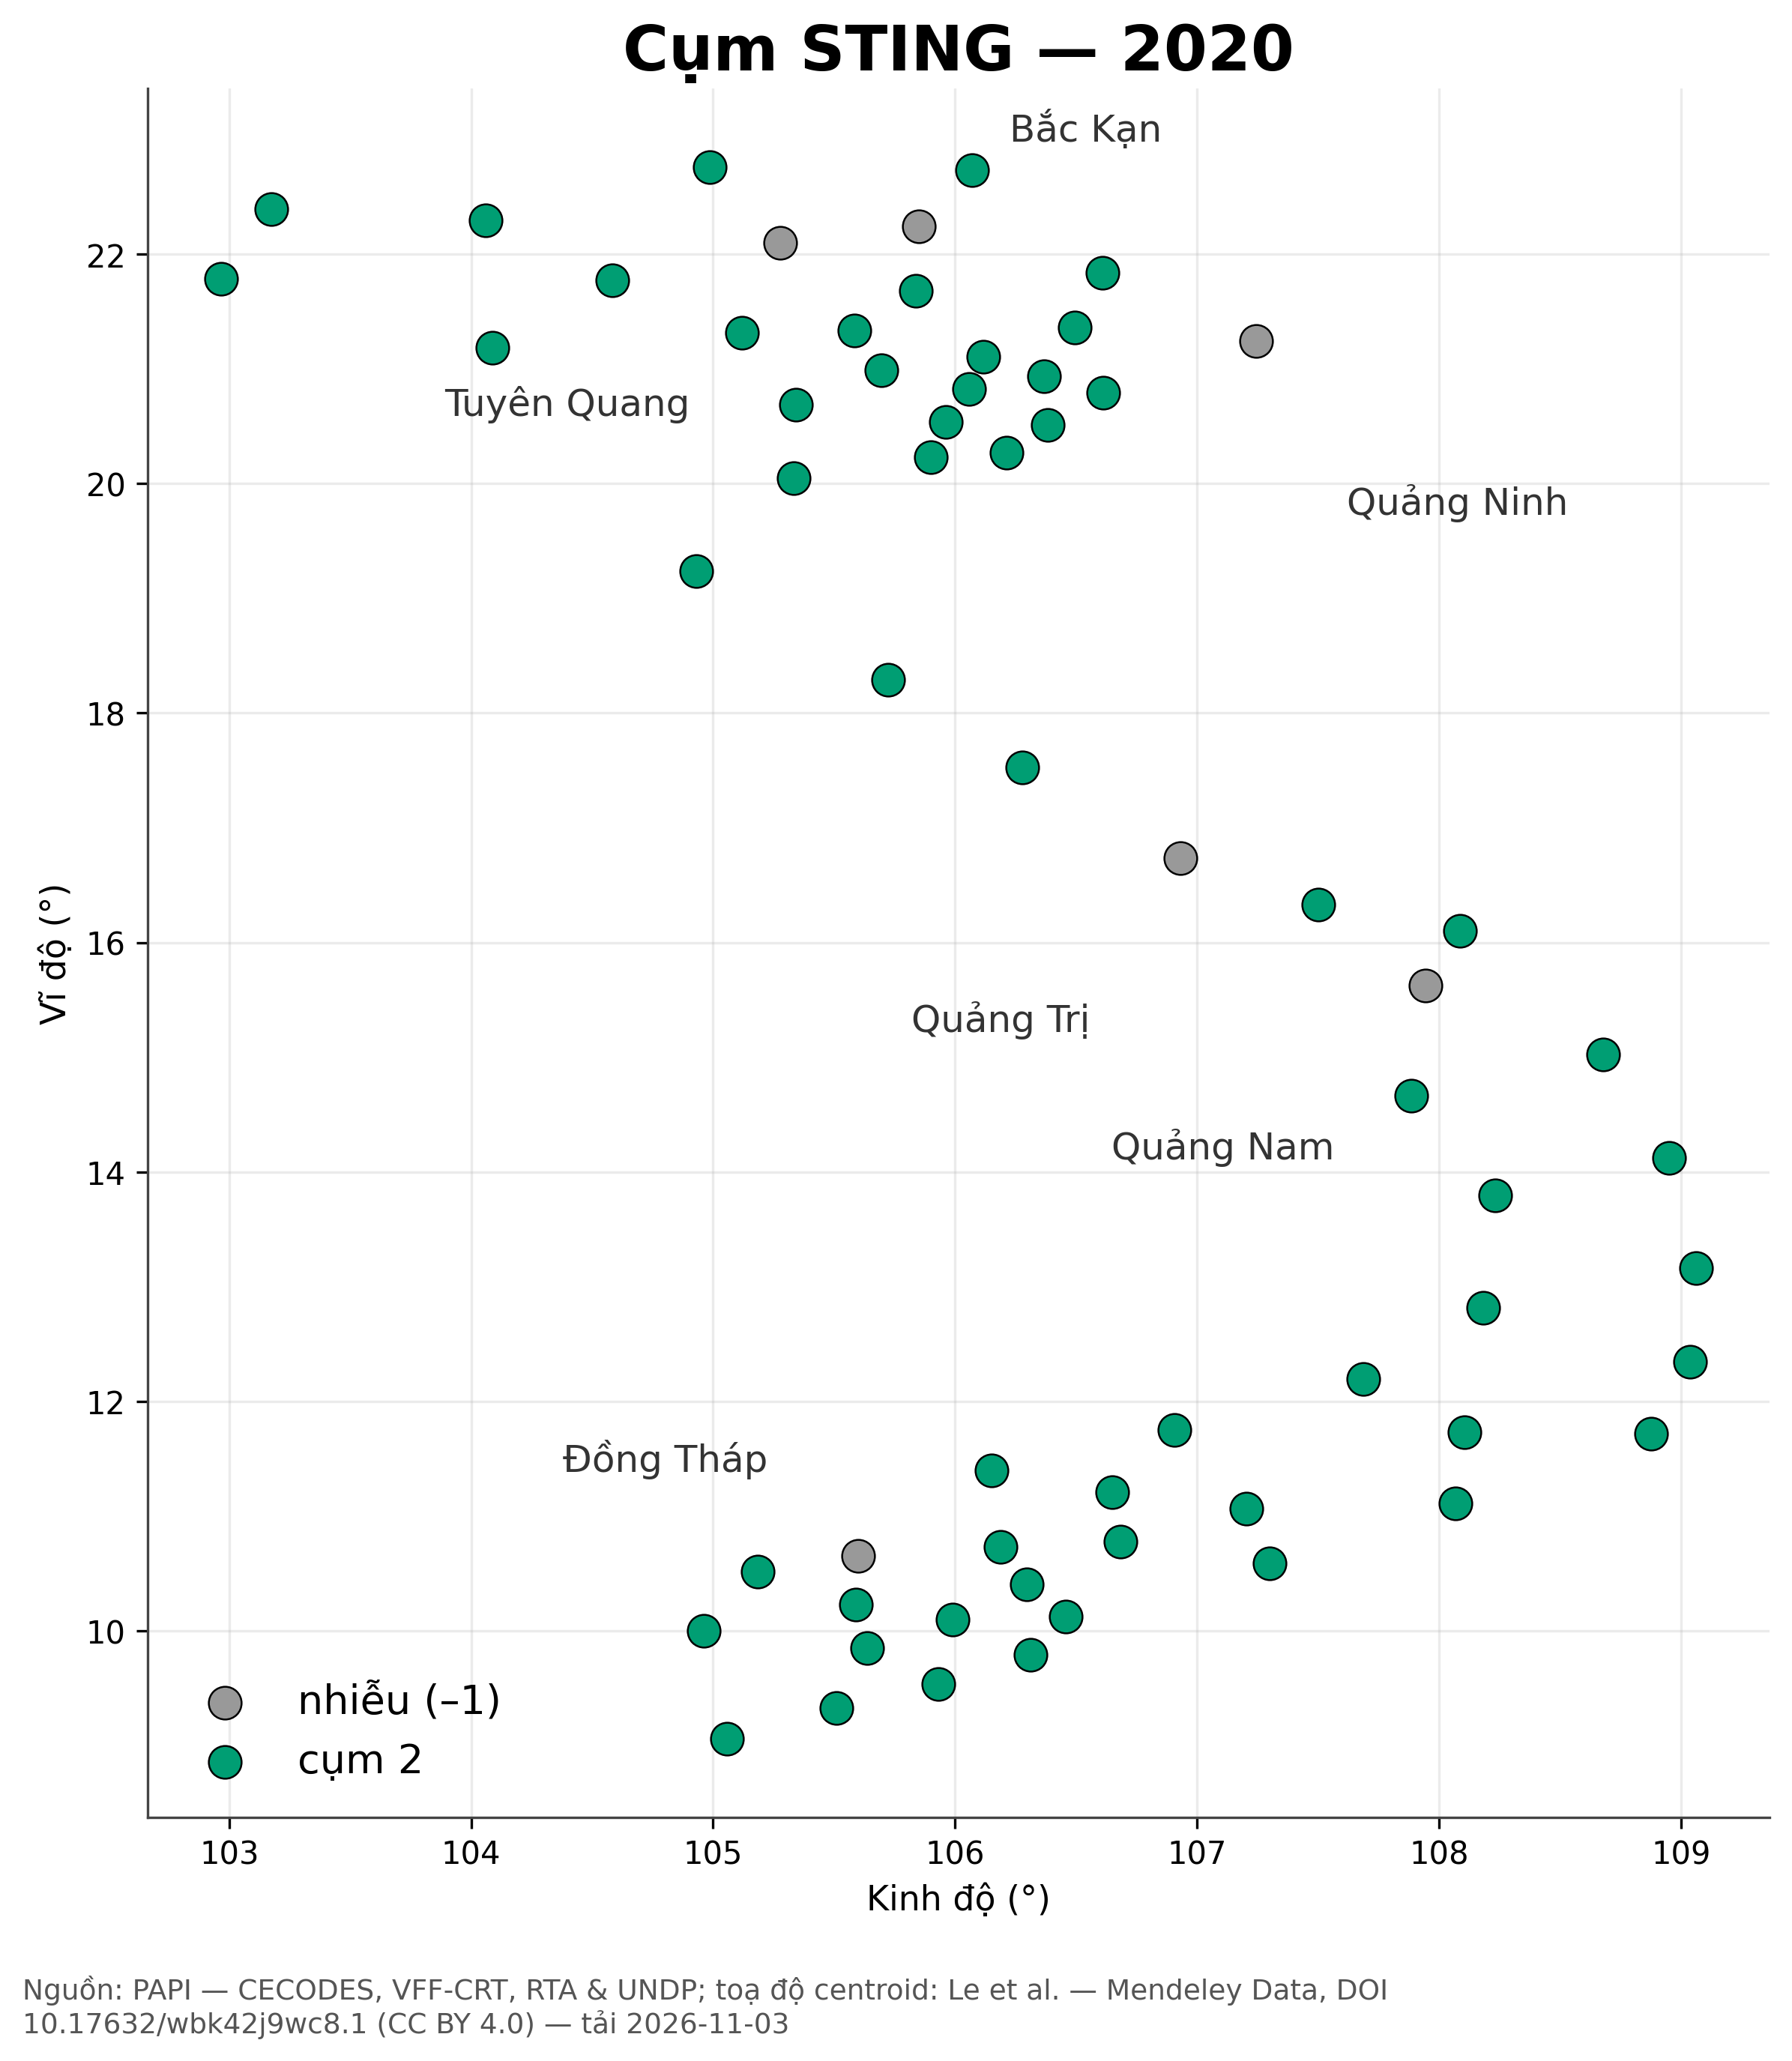

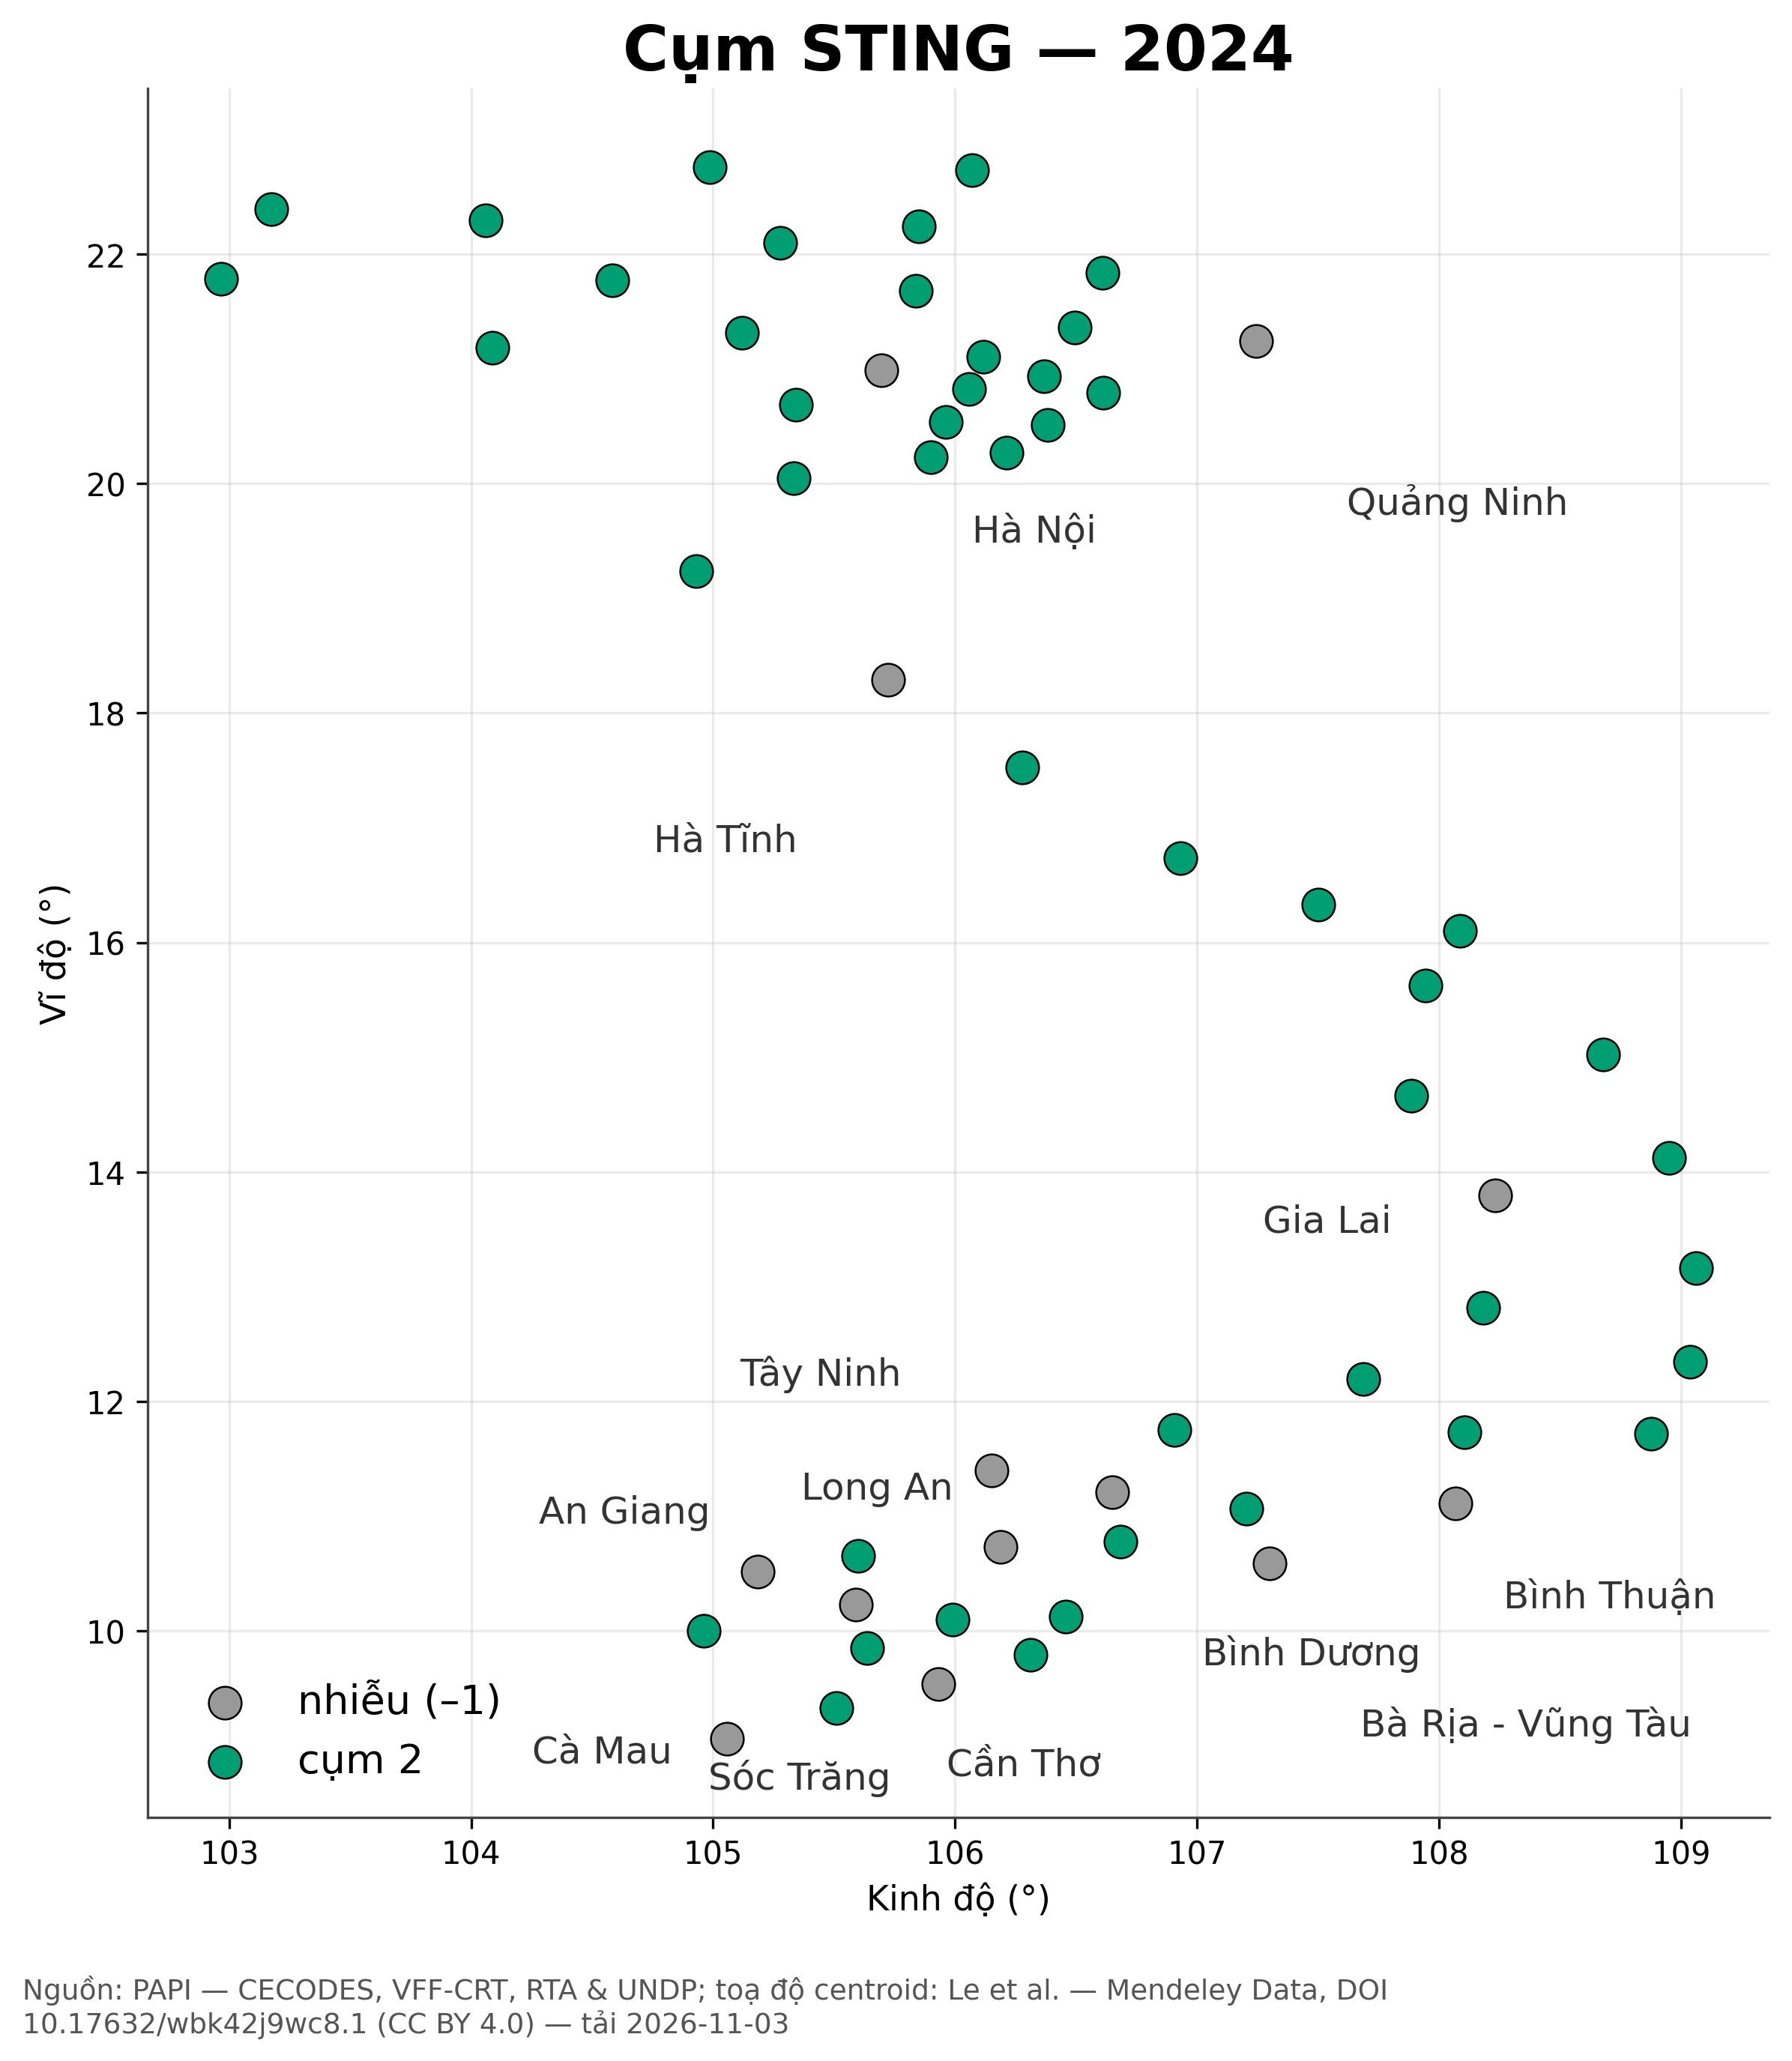

In [6]:
from IPython.display import Image, display
for year in (2020, 2024):
    display(Image(filename=f"../results/figs/map_{year}.png"))

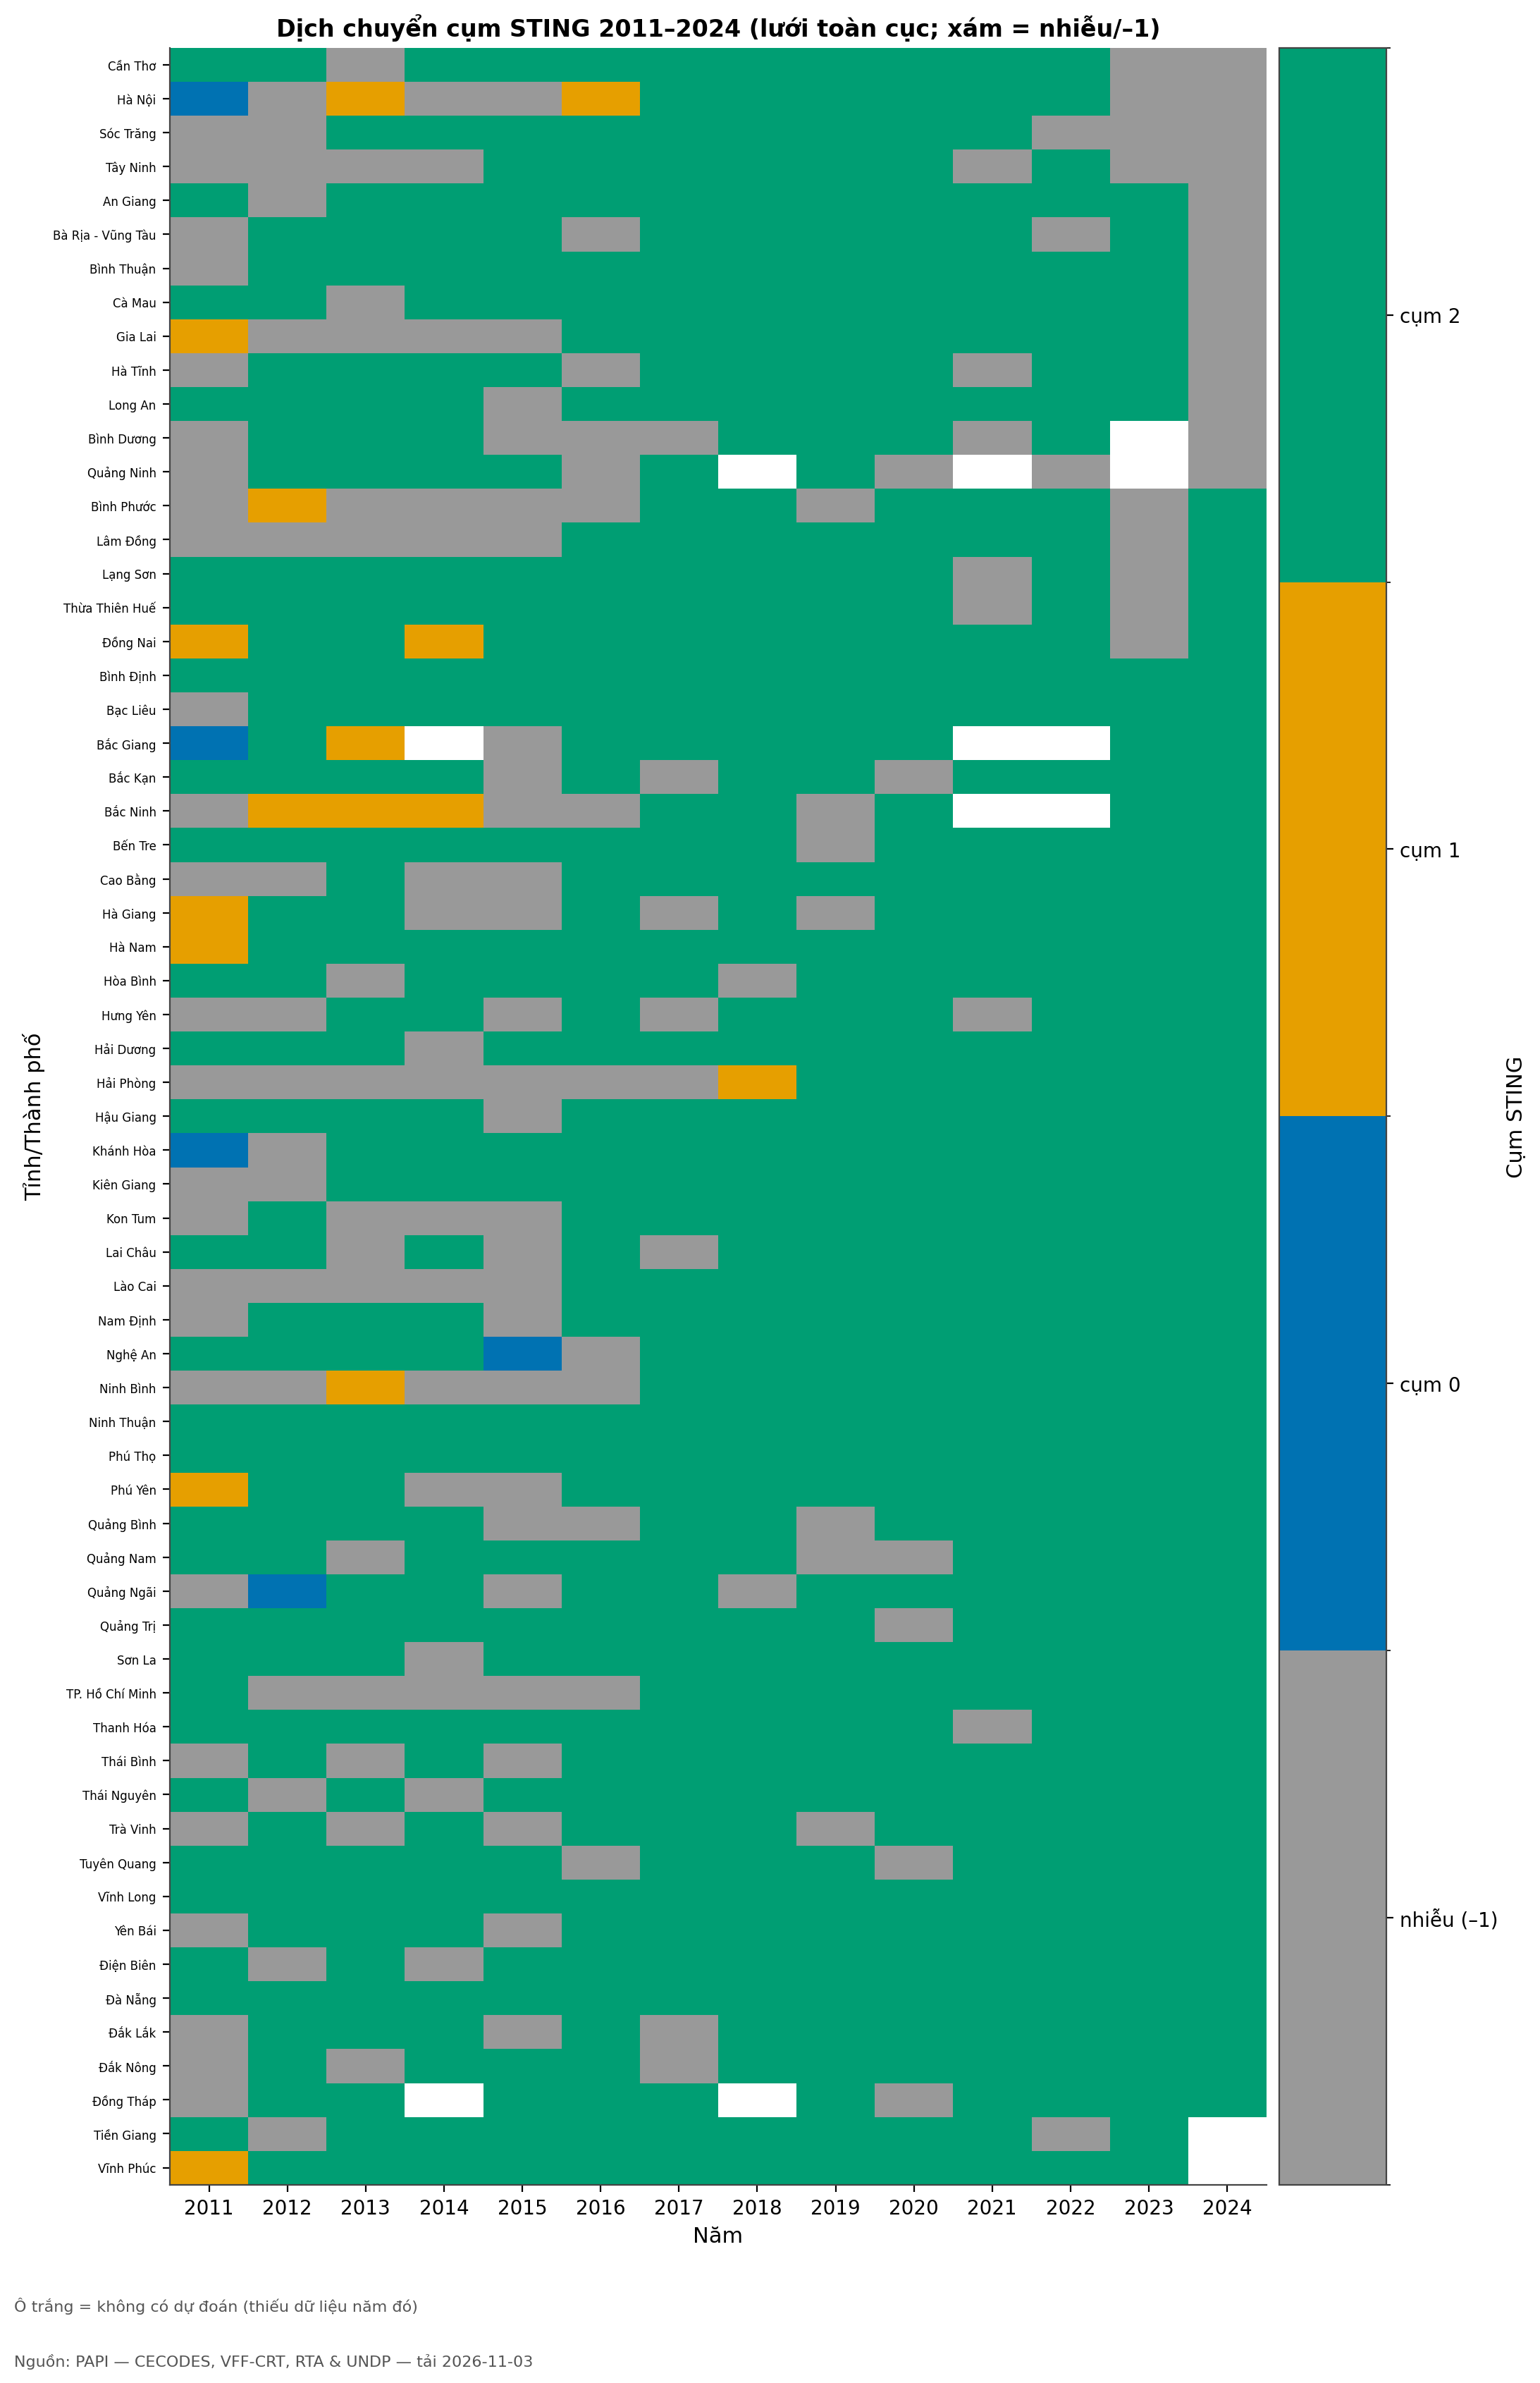

In [7]:
display(Image(filename="../results/figs/evolution.png"))

**Chú thích evolution:** lưới TOÀN CỤC (không refit per-year) để nhãn có thể so sánh giữa các năm;
xám = nhiễu (−1); trắng = thiếu chỉ tiêu năm đó. Đọc được xu hướng: phần lớn tỉnh nằm trong cụm lớn
trong mọi năm; một số tỉnh vào/ra vùng ngoại vi theo thời gian.

## 6. Pipeline dự đoán (năm 2024 — out-of-sample)

1. **STING.predict:** gán tỉnh vào ô lưới đã học — 48/61 tỉnh đủ chỉ tiêu → cụm lớn, 13 → nhiễu.
2. **Model giám sát:** Ridge được chọn theo CV để dự báo *6.1 Y tế công lập* năm sau; MAE holdout 2023→2024 thấp hơn carry-forward **6.3%**
   (xem `results/supervised_metrics.csv`).
3. **Phân loại ngoại vi (khám phá, không phải bằng chứng tổng quát hóa):** điểm holdout vượt baseline
   majority trên đúng một năm, nhưng nhãn là pseudo-label do STING sinh và cấu hình gán nhãn được chọn
   trên 2021–2022 — trùng 2 fold CV cuối — nên chỉ đọc như khảo sát; xem `results/supervised_summary.md`.

In [8]:
sup = pd.read_csv("../results/supervised_metrics.csv")
show_md(sup.to_markdown(index=False))

| task           | model                               | metric_cv                             |   value_cv |   holdout_mae |   holdout_rmse |   holdout_r2 |   holdout_acc |   holdout_macro_f1 |
|:---------------|:------------------------------------|:--------------------------------------|-----------:|--------------:|---------------:|-------------:|--------------:|-------------------:|
| regression     | carry-forward (giữ giá trị năm nay) | r2 (expanding origin 2017–2022)       |      0.145 |        0.0683 |         0.0875 |        0.198 |       nan     |            nan     |
| regression     | trung bình train                    | r2 (expanding origin 2017–2022)       |     -0.77  |        0.0814 |         0.1027 |       -0.105 |       nan     |            nan     |
| regression     | ridge                               | r2 (expanding origin 2017–2022)       |      0.265 |        0.064  |         0.0769 |        0.381 |       nan     |            nan     |
| regression     | random forest                       | r2 (expanding origin 2017–2022)       |      0.197 |        0.0616 |         0.0742 |        0.423 |       nan     |            nan     |
| classification | majority (lớp đa số)                | f1_macro (expanding origin 2017–2022) |      0.228 |      nan      |       nan      |      nan     |         0.186 |              0.157 |
| classification | logistic regression                 | f1_macro (expanding origin 2017–2022) |      0.434 |      nan      |       nan      |      nan     |         0.644 |              0.541 |
| classification | random forest                       | f1_macro (expanding origin 2017–2022) |      0.397 |      nan      |       nan      |      nan     |         0.678 |              0.6   |

In [9]:
import joblib
import sys
sys.path.insert(0, str(Path("../scripts").resolve()))
from papi_pred_common import REGRESSION_FEATURES
from predict_supervised import build_regression_pairs, expanding_origin_folds

print("8 regression features:", REGRESSION_FEATURES)
regression_pairs = build_regression_pairs(panel)
training_origins = regression_pairs.loc[
    regression_pairs.year_t < 2023, "year_t"
].to_numpy()
print("Regression folds use training origins only (year_t < 2023).")
folds = expanding_origin_folds(training_origins, first_validation_origin=2017)
for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):
    print(
        f"Fold {fold_number}: max train origin={training_origins[train_idx].max()}, "
        f"validation origin={training_origins[val_idx][0]}"
    )

regression_metrics = pd.read_csv("../results/supervised_metrics.csv")
regression_models = regression_metrics[
    (regression_metrics.task == "regression")
    & ~regression_metrics.model.isin(
        ["carry-forward (giữ giá trị năm nay)", "trung bình train"]
    )
].dropna(subset=["value_cv"])
chosen = regression_models.loc[regression_models.value_cv.idxmax()]
print(f"CV-selected regression model: {chosen.model} (R²={chosen.value_cv:.3f})")

print("Loading ../models/sup_ridge.joblib")
ridge = joblib.load("../models/sup_ridge.joblib")
probe = np.array([[1.5, 2.6, 2.0, 2.1, 1.9, 1.7, 1.9, 1.8]])
print("Fixed 8-feature probe:", probe.tolist()[0])
print("Ridge prediction:", ridge.predict(probe).tolist())

8 regression features: ['sd_1_3', 'sd_1_4', 'sd_4_1', 'sd_4_2', 'sd_4_3', 'sd_4_4', 'sd_6_1', 'sd_6_3']


Regression folds use training origins only (year_t < 2023).
Fold 1: max train origin=2016, validation origin=2017
Fold 2: max train origin=2017, validation origin=2018
Fold 3: max train origin=2018, validation origin=2019
Fold 4: max train origin=2019, validation origin=2020
Fold 5: max train origin=2020, validation origin=2021
Fold 6: max train origin=2021, validation origin=2022
CV-selected regression model: ridge (R²=0.265)
Loading ../models/sup_ridge.joblib
Fixed 8-feature probe: [1.5, 2.6, 2.0, 2.1, 1.9, 1.7, 1.9, 1.8]
Ridge prediction: [1.9682530855137745]


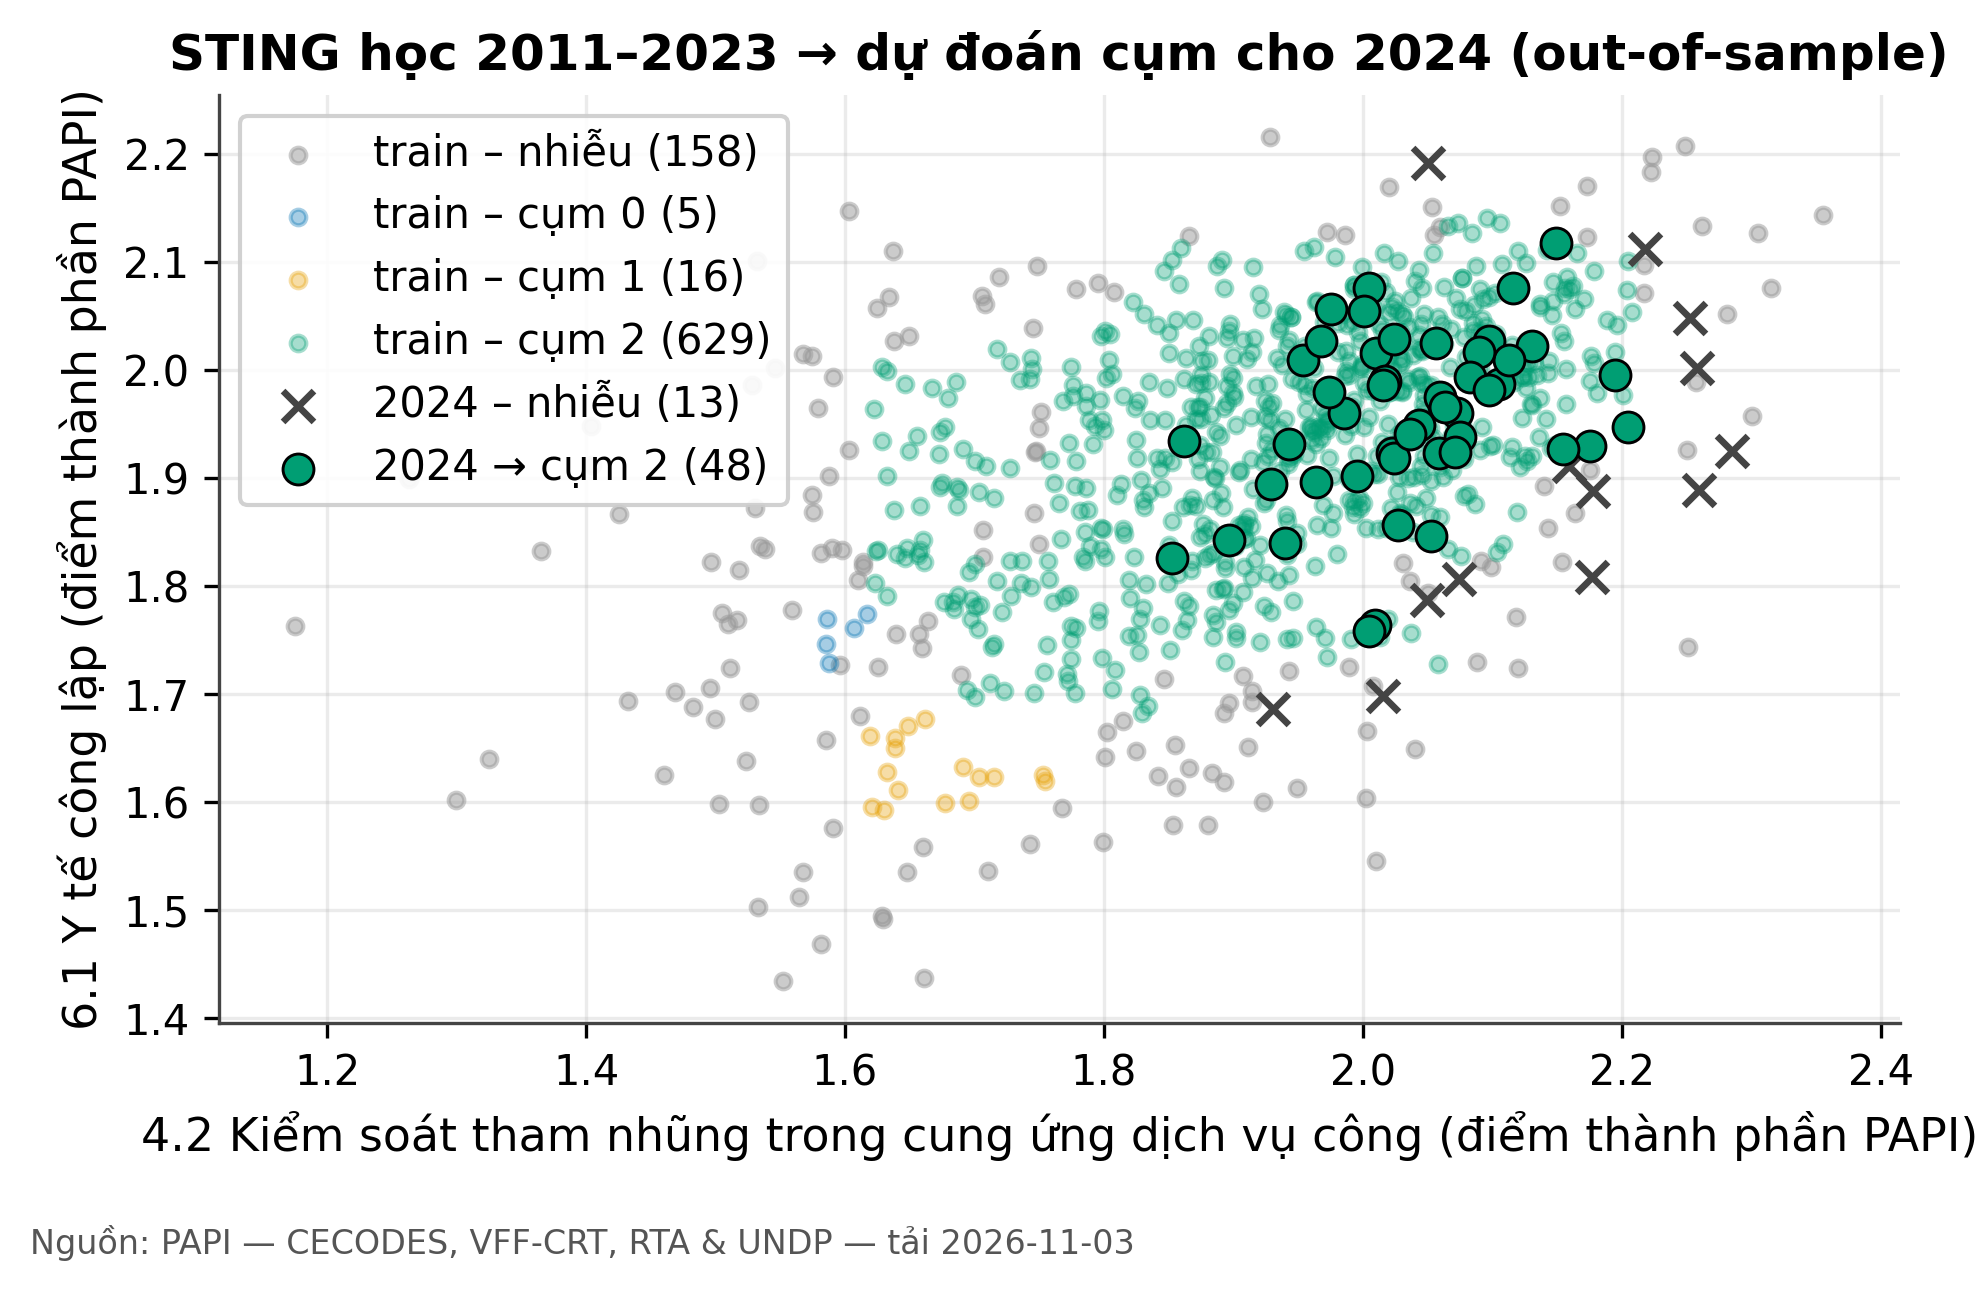

In [10]:
display(Image(filename="../results/figs/predict_2024.png"))

## 7. Kiểm chứng bổ trợ — nghèo GSO theo nhãn cụm (cửa sổ giao 2012–2016 & 2020–2024)

- Nguồn độc lập thứ hai sau PCI: tỷ lệ hộ nghèo cấp tỉnh **GSO pxweb V14.47** (thống kê chính thức,
  tách khỏi PAPI là khảo sát hộ dân) — KHÔNG vào feature, KHÔNG nội suy ô thiếu (TP.HCM 2016 thiếu phía nguồn).
- Mọi số dưới đây **đọc trực tiếp từ `results/poverty_validation.csv`** (sinh bởi `scripts/poverty_validation.py`) — không hardcode.
- Hai kiểm định bắt buộc **đọc cùng nhau**: gộp thô (nhiễm hiệu ứng năm — chuẩn nghèo đổi theo giai đoạn,
  median nghèo giảm sâu xuyên giai đoạn) và đã-trừ-median-trong-năm (tách hiệu ứng năm).

| section                 | group      |   year |   n |   mean |   median |   std |   min |   max |   note |
|:------------------------|:-----------|-------:|----:|-------:|---------:|------:|------:|------:|-------:|
| poverty_pooled_raw      | nhiễu (–1) |    nan | 144 |  9.872 |     6.6  | 9.937 |   0   |  42.3 |    nan |
| poverty_pooled_raw      | cụm 0      |    nan |   2 | 14.95  |    14.95 | 3.748 |  12.3 |  17.6 |    nan |
| poverty_pooled_raw      | cụm 1      |    nan |  10 |  4.55  |     3.25 | 3.641 |   1.2 |  12.1 |    nan |
| poverty_pooled_raw      | cụm 2      |    nan | 649 |  9.008 |     6.2  | 8.729 |   0   |  50.2 |    nan |
| poverty_pooled_demeaned | nhiễu (–1) |    nan | 144 |  2.124 |    -1.05 | 9.071 | -12.8 |  33.7 |    nan |
| poverty_pooled_demeaned | cụm 0      |    nan |   2 |  4.5   |     4.5  | 0.283 |   4.3 |   4.7 |    nan |
| poverty_pooled_demeaned | cụm 1      |    nan |  10 | -6.035 |    -6.2  | 2.848 |  -9   |   0.2 |    nan |
| poverty_pooled_demeaned | cụm 2      |    nan | 649 |  2.444 |     0    | 8.378 | -12.8 |  42.3 |    nan |

| section                 | group                                           |   n | note                              |
|:------------------------|:------------------------------------------------|----:|:----------------------------------|
| poverty_pooled_raw      | ANOVA F(3,801)                                  | 805 | F = 1.5376; p = 0.203             |
| poverty_pooled_raw      | Kruskal–Wallis                                  | 805 | H = 4.6670; p = 0.198             |
| poverty_pooled_raw      | eta squared                                     | 805 | eta² = 0.0057 (SS giữa / SS tổng) |
| poverty_pooled_demeaned | ANOVA F(3,801)                                  | 805 | F = 3.3629; p = 0.0183            |
| poverty_pooled_demeaned | Kruskal–Wallis                                  | 805 | H = 20.6285; p = 0.000126         |
| poverty_pooled_demeaned | eta squared                                     | 805 | eta² = 0.0124 (SS giữa / SS tổng) |
| test_mw_noise_vs_c2     | Mann–Whitney nhiễu vs cụm 2 (thô)               | 793 | U = 47464; p = 0.767              |
| test_mw_noise_vs_c2     | Mann–Whitney nhiễu vs cụm 2 (đã trừ median năm) | 793 | U = 43978; p = 0.269              |


Gộp thô:                 H = 4.6670; p = 0.198
Đã trừ median trong năm: H = 20.6285; p = 0.000126
Mann–Whitney nhiễu vs cụm 2 (thô): U = 47464; p = 0.767
Mann–Whitney nhiễu vs cụm 2 (đã trừ median năm): U = 43978; p = 0.269

Đọc trung thực: gộp thô KHÔNG đáng kể (nhiễm hiệu ứng năm); đã-trừ-median-năm đáng kể ở mức yếu.
Cặp tương phản đáng tin duy nhất là nhiễu vs cụm 2 (cụm 0 n=2, cụm 1 n=10 quá nhỏ):
không khác biệt ở mức gộp, biên sau khi tách năm → nghèo GSO là kiểm chứng bổ trợ,
không thay thế kiểm định chính PCI (số liệu đầy đủ: results/poverty_validation.md).


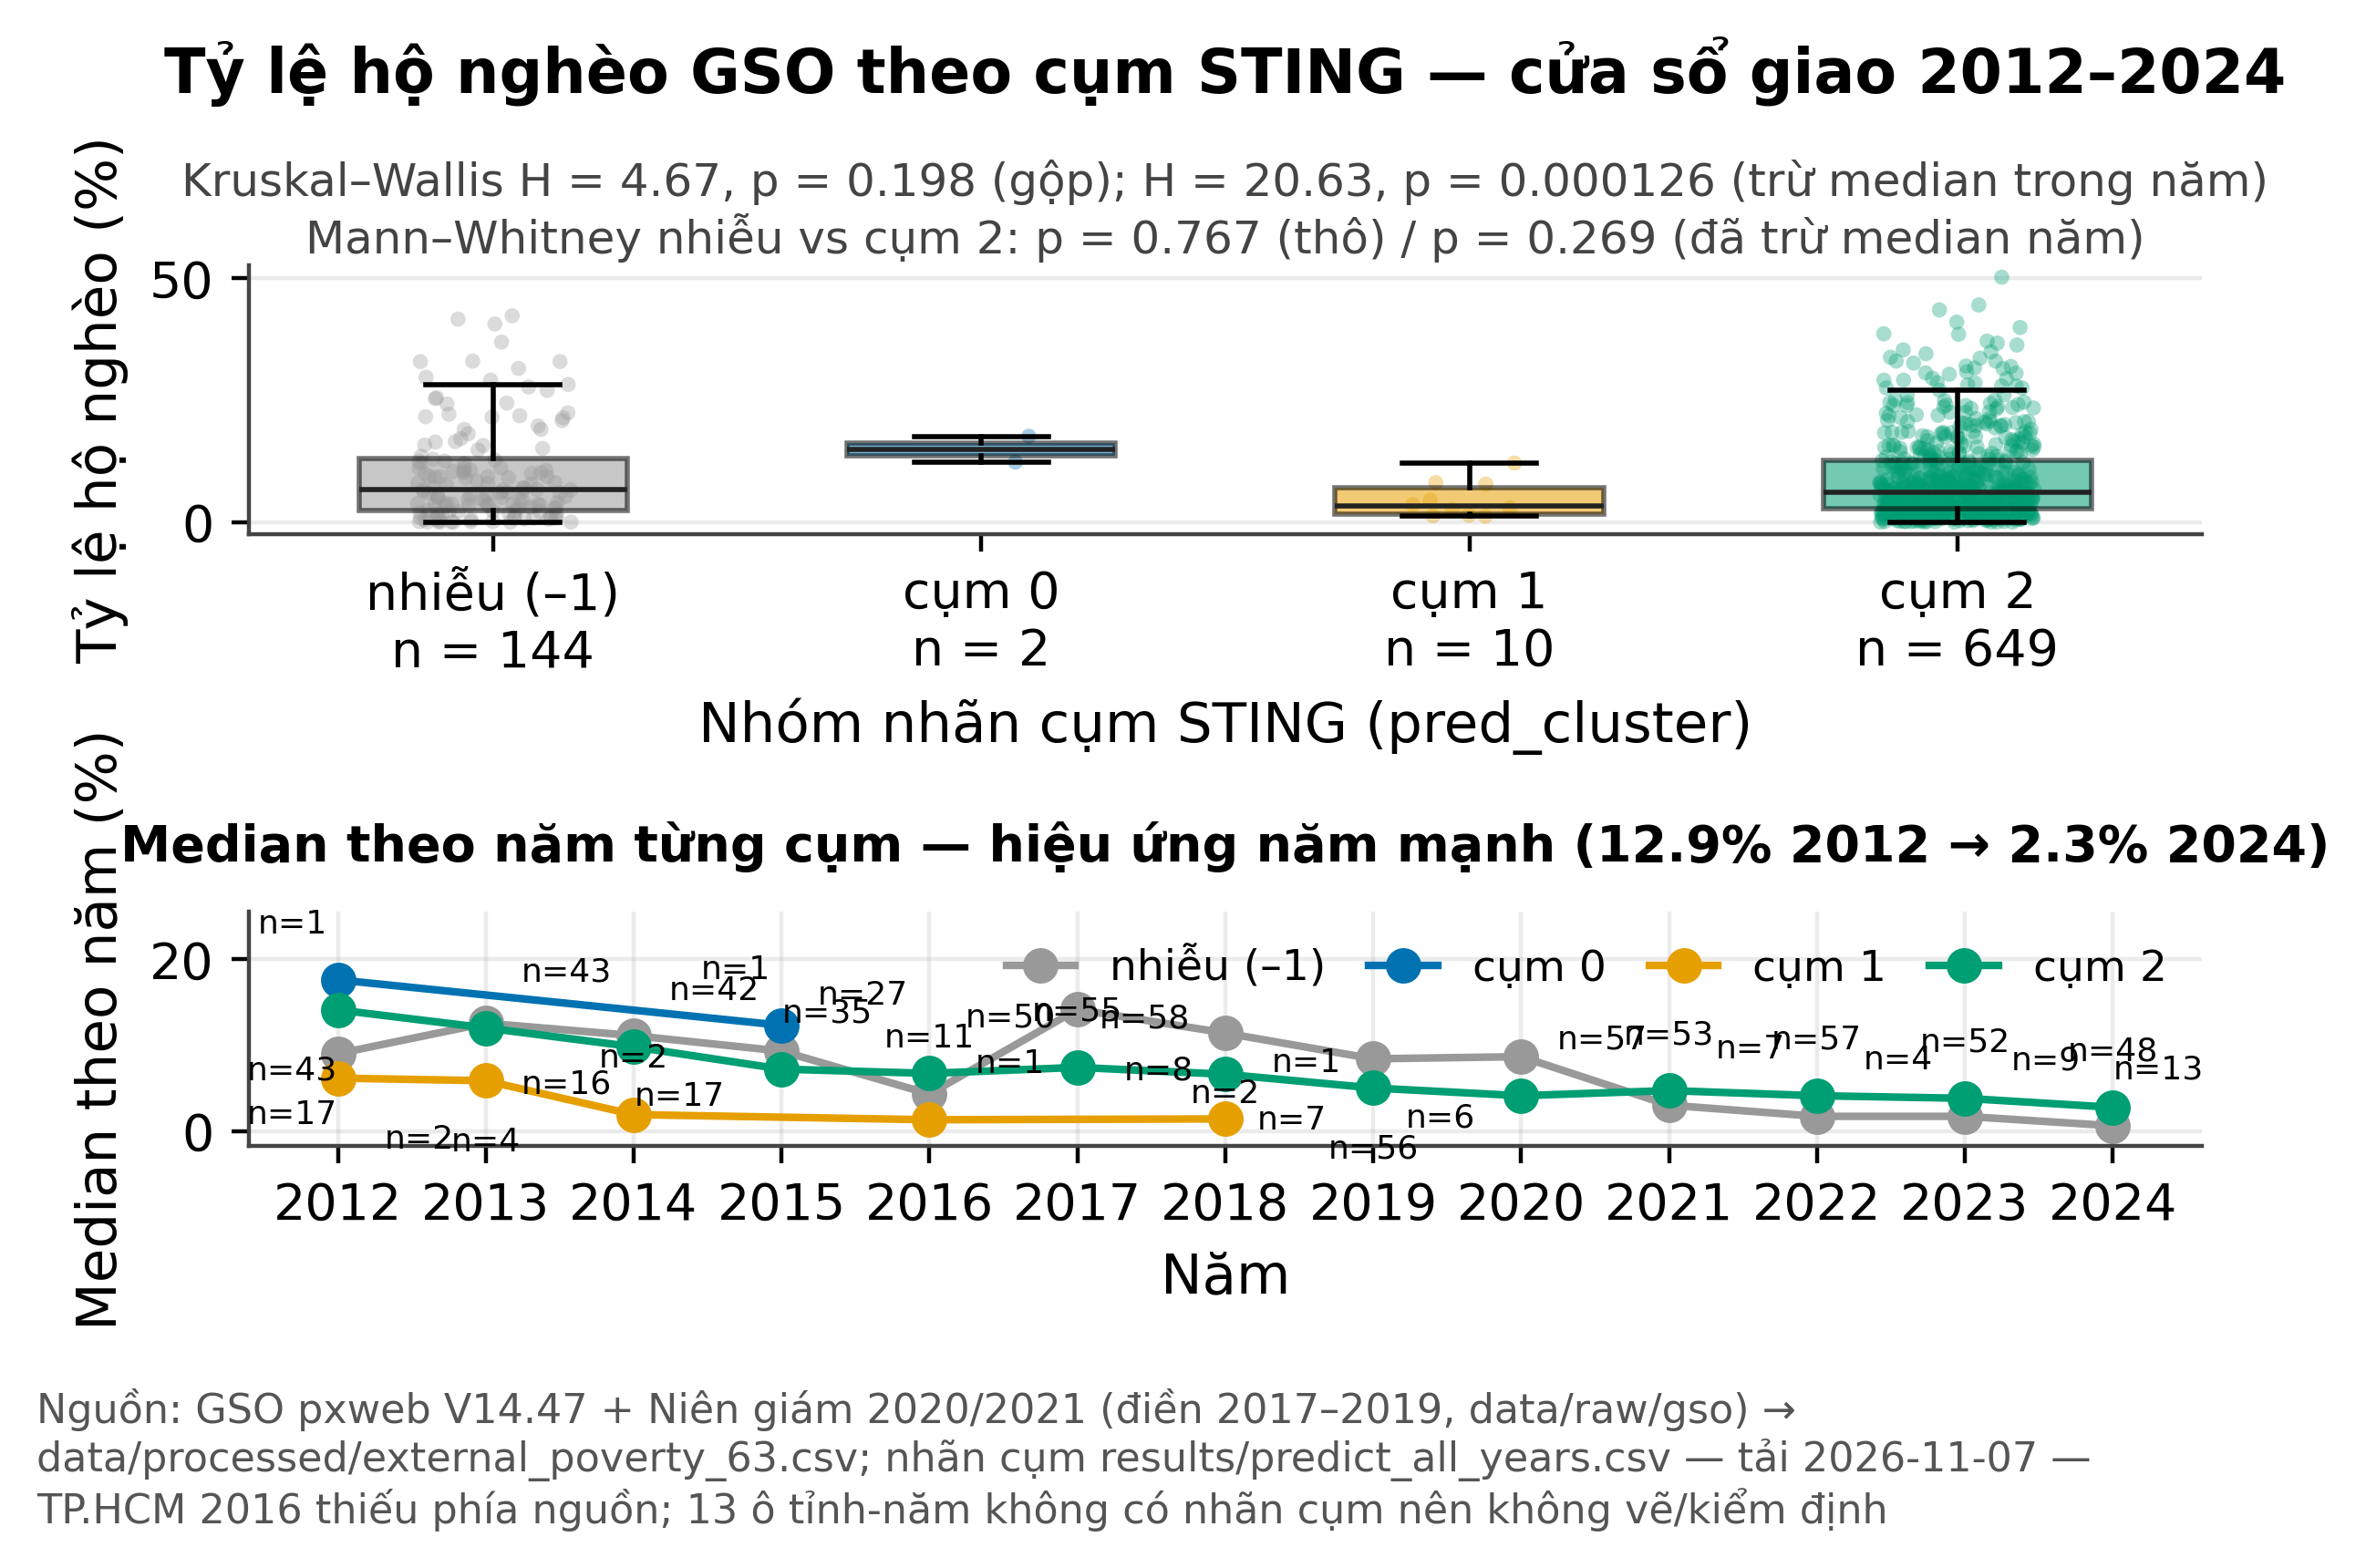

In [11]:
pov = pd.read_csv("../results/poverty_validation.csv")

pooled_sections = ["poverty_pooled_raw", "poverty_pooled_demeaned", "test_mw_noise_vs_c2"]
pov_pool = pov[pov.section.isin(pooled_sections)].copy()
has_stats = pov_pool["mean"].notna() & pov_pool["mean"].astype(str).str.strip().ne("")
has_note = pov_pool["note"].notna() & pov_pool["note"].astype(str).str.strip().ne("")
show_md(pov_pool[has_stats].to_markdown(index=False))
print()
show_md(pov_pool[has_note][["section", "group", "n", "note"]].to_markdown(index=False))
print()

def _pov_note(section, group):
    return str(pov[(pov.section == section) & (pov.group == group)].iloc[0]["note"])

print("Gộp thô:                ", _pov_note("poverty_pooled_raw", "Kruskal–Wallis"))
print("Đã trừ median trong năm:", _pov_note("poverty_pooled_demeaned", "Kruskal–Wallis"))
for _, r in pov[pov.section == "test_mw_noise_vs_c2"].iterrows():
    print(f"{r['group']}: {r['note']}")
print()
_c0 = int(pov_pool[has_stats & pov_pool["group"].str.contains("cụm 0", regex=False)].iloc[0]["n"])
_c1 = int(pov_pool[has_stats & pov_pool["group"].str.contains("cụm 1", regex=False)].iloc[0]["n"])
print("Đọc trung thực: gộp thô KHÔNG đáng kể (nhiễm hiệu ứng năm); đã-trừ-median-năm đáng kể ở mức yếu.")
print(f"Cặp tương phản đáng tin duy nhất là nhiễu vs cụm 2 (cụm 0 n={_c0}, cụm 1 n={_c1} quá nhỏ):")
print("không khác biệt ở mức gộp, biên sau khi tách năm → nghèo GSO là kiểm chứng bổ trợ,")
print("không thay thế kiểm định chính PCI (số liệu đầy đủ: results/poverty_validation.md).")

display(Image(filename="../results/figs/external_poverty_by_cluster.png"))

## 8. Kết luận

- STING tự viết hoạt động đúng trên dữ liệu giả lập (ARI=0.950) và trên dữ liệu thật; kết quả thật
  cho thấy **dữ liệu PAPI cấp tỉnh/năm gần như một khối** — cấu trúc tách biệt rất yếu và chỉ ở ngoại vi.
- Giá trị của nghiên cứu: (a) cài đặt STING từ đầu + bộ kiểm thử; (b) quy trình chọn cấu hình **train-only**
  chống "chọn theo test"; (c) audit thang đo dữ liệu đa năm; (d) pipeline dự đoán 2 mô hình local,
  có so sánh baseline và kết quả âm tính ghi trung thực.
- Hạn chế: lưới song song trục; metric hình học không bản địa; robustness không nhận diện cấu trúc khi mở rộng chiều;
  gãy thang đo ở 23/37 cột; dữ liệu 1 năm chỉ 61 điểm → nhiễu cao.
- Hướng phát triển: chuẩn hóa theo hạng (rank) xuyên năm; mở rộng chỉ tiêu; dự báo chuỗi thời gian nhiều năm;
  phân cụm trên không gian nhiều năm liền kề (feature trajectory).

**Tài liệu tham khảo:** Wang, Yang & Muntz (VLDB'97) — STING; PAPI (CECODES/VFF-CRT/RTA/UNDP);
Le et al., Mendeley Data (DOI 10.17632/wbk42j9wc8.1, CC BY 4.0); Open Development Vietnam (CC-BY-SA 4.0).